NICOLAS MORENO - SEBASTIAN LUIS - DANIEL ESLAVA


In [1]:
import glob, os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.model_selection import train_test_split, KFold, StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import RidgeCV, LogisticRegression
from sklearn.ensemble import (RandomForestRegressor, HistGradientBoostingRegressor,
                              RandomForestClassifier, HistGradientBoostingClassifier)
from sklearn.calibration import CalibratedClassifierCV
from sklearn.inspection import permutation_importance
from sklearn.metrics import (r2_score, mean_absolute_error, mean_squared_error,
                             roc_auc_score, average_precision_score)

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid", context="notebook")
AZUL, ROJO, GRIS = "#1F4E79", "#C0392B", "#7F8C8D"
pd.options.display.float_format = "{:,.2f}".format
pd.options.display.max_columns = 60

# Supuestos económicos del caso
MARGEN = 0.25              # margen de FEMSA sobre ventas al público
COSTO_NEVERA = 60_000      # COP por mes por nevera
VALOR_NO_CAMBIO = 500_000  # COP: valor de evitar un cambio de proveedor
COSTO_RETENCION = 50_000   # COP por acción de retención
EFECT_RETENCION = 0.40     # efectividad de la retención
N_NEVERAS = 1_000

In [2]:

archivos = glob.glob("*refrescos*nevera*.csv")
if not archivos:
    try:
        from google.colab import files
        files.upload()
        archivos = glob.glob("*refrescos*nevera*.csv")
    except ImportError:
        raise FileNotFoundError("Pon el CSV en la carpeta de trabajo.")

df = pd.read_csv(archivos[0], encoding="utf-8-sig")
print(f"{df.shape[0]:,} tiendas x {df.shape[1]} columnas | id_tienda único: {df.id_tienda.is_unique}")
print(f"Valores nulos en total: {int(df.isna().sum().sum())} | filas duplicadas: {int(df.duplicated().sum())}")
df.head(3)

Sube base_refrescos_nevera.csv


Saving base_ refrescos_nevera.csv to base_ refrescos_nevera.csv
38,000 tiendas x 109 columnas | id_tienda único: True
Valores nulos en total: 0 | filas duplicadas: 0


,id_tienda,region,departamento,ciudad,latitud,longitud,zona,estrato,temperatura_media_c,poblacion_500m,n_tiendas_competencia_500m,dist_hard_discount_km,cerca_colegio,cerca_parada_transporte,cerca_universidad_oficinas,dist_cedi_km,tipo_negocio,area_m2,antiguedad_anios,dias_abre_semana,horas_abre_dia,num_empleados,tiene_datafono,acepta_pago_digital,ofrece_domicilios,tiene_mesas_consumo,vende_licor,n_referencias_total,nevera_propia_tienda,nevera_otras_marcas,...,cop_sprite_400ml,cop_brisa_600ml,cop_delvalle_fresh_400ml,cop_powerade_500ml,cop_fuze_tea_400ml,cop_colombiana_400ml,cop_manzana_400ml,cop_manzana_1500ml,cop_pepsi_400ml,cop_sevenup_400ml,cop_cristal_600ml,cop_hit_500ml,cop_mr_tea_500ml,cop_squash_500ml,cop_speedmax_250ml,unidades_femsa_mes,unidades_postobon_mes,ventas_femsa_cop_mes,ventas_postobon_cop_mes,ventas_bebidas_cop_mes,share_femsa_valor,n_skus_activos_femsa,n_skus_activos_postobon,proveedor_principal,ventas_otras_categorias_cop_mes,ventas_totales_tienda_cop_mes,ticket_promedio_cop,ventas_por_m2_cop,peso_bebidas_en_ventas,cambio_proveedor_principal_6m
0,T00001,Centro,Bogotá D.C.,Bogotá,4.73,-74.10,Urbana,3,14.80,4440,1,1.62,0,0,0,8.90,Tienda de barrio,26.40,4.60,7,10.20,2,0,1,0,1,1,212,0,1,...,99970,23350,0,33000,27790,49690,0,0,23960,39930,0,0,29580,0,3450,118,53,356070,146610,502680,0.71,8,5,FEMSA,8000900,8503580,5400,322110,0.06,0
1,T00002,Caribe,Atlántico,Barranquilla,11.01,-74.78,Urbana,4,28.00,4400,5,0.63,1,1,0,5.50,Tienda de barrio,53.40,6.00,7,14.10,1,1,1,1,1,1,227,0,1,...,93220,54340,8060,20410,20620,0,112780,186900,57100,51660,243690,163130,60420,81060,70490,230,339,838150,1027230,1865380,0.45,10,9,Postobón,14949400,16814780,8810,314880,0.11,0
2,T00003,Antioquia,Antioquia,Bello,6.33,-75.62,Urbana,3,22.40,8480,13,0.28,0,1,0,3.00,Minimercado,50.30,10.20,6,14.30,1,0,1,1,0,1,263,0,1,...,273080,278680,0,123530,136310,360210,900520,396760,110270,104750,276280,113330,88830,142940,39310,600,826,1972050,2533200,4505250,0.44,8,10,Postobón,31273500,35778750,11770,711310,0.13,0


In [3]:
# 1.1 Las tiendas
for c in ["region", "zona", "tipo_negocio"]:
    display(df[c].value_counts(normalize=True).rename("proporción").to_frame().round(3).T)
display(df[["estrato", "temperatura_media_c", "poblacion_500m", "area_m2", "clientes_prom_dia",
            "n_tiendas_competencia_500m", "antiguedad_anios"]].describe().T)

region,Centro,Caribe,Antioquia,Pacífica,Santanderes,Eje Cafetero,Orinoquía
proporción,0.35,0.20,0.15,0.14,0.07,0.06,0.03


zona,Urbana,Periurbana,Rural
proporción,0.82,0.13,0.05


tipo_negocio,Tienda de barrio,Minimercado,Panadería,Cafetería,Licorera,Miscelánea
proporción,0.64,0.14,0.08,0.05,0.05,0.04


,count,mean,std,min,25%,50%,75%,max
estrato,"38,000.00",2.55,1.16,1.00,2.00,2.00,3.00,6.00
temperatura_media_c,"38,000.00",21.11,5.56,10.40,14.70,22.10,26.30,30.90
poblacion_500m,"38,000.00","7,416.71","4,808.72",210.00,"4,130.00","6,330.00","9,470.00","45,000.00"
area_m2,"38,000.00",41.21,32.50,6.00,22.40,31.10,46.40,515.10
clientes_prom_dia,"38,000.00",70.91,35.19,10.00,46.00,63.00,87.00,479.00
n_tiendas_competencia_500m,"38,000.00",5.16,2.69,0.00,3.00,5.00,7.00,21.00
antiguedad_anios,"38,000.00",9.98,7.09,0.20,4.80,8.40,13.40,50.00


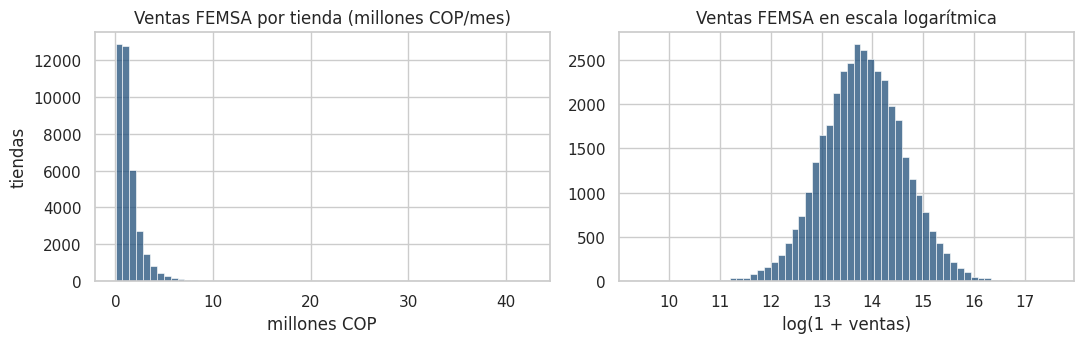

count       38,000.00
mean     1,373,919.00
std      1,335,611.00
min         12,380.00
25%        589,068.00
50%        990,100.00
75%      1,691,380.00
max     42,346,490.00
Name: ventas_femsa_cop_mes, dtype: float64


In [4]:
# 1.2 Las ventas de FEMSA: muy asimétricas -> usaremos log(1 + ventas)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
sns.histplot(df.ventas_femsa_cop_mes / 1e6, bins=60, color=AZUL, ax=ax[0])
ax[0].set(title="Ventas FEMSA por tienda (millones COP/mes)", xlabel="millones COP", ylabel="tiendas")
sns.histplot(np.log1p(df.ventas_femsa_cop_mes), bins=60, color=AZUL, ax=ax[1])
ax[1].set(title="Ventas FEMSA en escala logarítmica", xlabel="log(1 + ventas)", ylabel="")
plt.tight_layout(); plt.show()
print(df.ventas_femsa_cop_mes.describe().round(0))

In [5]:
# 1.3 Las neveras
print(df.presencia_neveras.value_counts().to_frame("tiendas").assign(pct=lambda x: (x.tiendas / len(df)).round(3)))
print("\nNeveras de FEMSA que NO funcionan:",
      f"{(df.loc[df.nevera_femsa == 1, 'nevera_femsa_operativa'] == 0).mean():.1%}")

                   tiendas  pct
presencia_neveras              
Ambas                13915 0.37
Solo FEMSA           11154 0.29
Ninguna               6483 0.17
Solo Postobón         6448 0.17

Neveras de FEMSA que NO funcionan: 15.2%


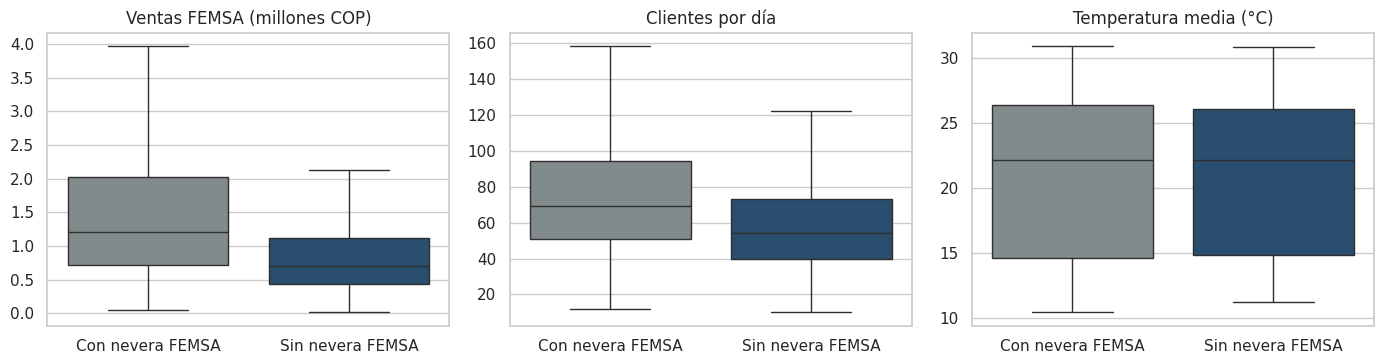

con_nevera,Con nevera FEMSA,Sin nevera FEMSA,diferencia %
ventas_femsa_cop_mes,"1,628,616.61","880,142.35",85.04
clientes_prom_dia,76.75,59.59,28.79
area_m2,44.56,34.72,28.35
estrato,2.58,2.49,3.70
temperatura_media_c,21.10,21.13,-0.14
poblacion_500m,"7,634.63","6,994.23",9.16
n_referencias_total,150.17,131.87,13.87
nevera_propia_tienda,0.42,0.40,4.86
nevera_postobon,0.56,0.50,11.31
cambio_proveedor_principal_6m,0.07,0.15,-52.67


Diferencia simple de ventas (con - sin): 748,474 COP/mes

OJO: las tiendas con nevera ya eran más grandes y tenían más clientes. Esa diferencia NO es todo efecto de la nevera (módulo 4).


In [6]:
# 1.4 Tiendas CON vs SIN nevera de FEMSA
df["con_nevera"] = df.nevera_femsa.map({1: "Con nevera FEMSA", 0: "Sin nevera FEMSA"})
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
sns.boxplot(data=df, x="con_nevera", y=df.ventas_femsa_cop_mes / 1e6, showfliers=False,
            palette=[GRIS, AZUL], ax=ax[0]); ax[0].set(title="Ventas FEMSA (millones COP)", xlabel="", ylabel="")
sns.boxplot(data=df, x="con_nevera", y="clientes_prom_dia", showfliers=False,
            palette=[GRIS, AZUL], ax=ax[1]); ax[1].set(title="Clientes por día", xlabel="", ylabel="")
sns.boxplot(data=df, x="con_nevera", y="temperatura_media_c",
            palette=[GRIS, AZUL], ax=ax[2]); ax[2].set(title="Temperatura media (°C)", xlabel="", ylabel="")
plt.tight_layout(); plt.show()

cols_cmp = ["ventas_femsa_cop_mes", "clientes_prom_dia", "area_m2", "estrato", "temperatura_media_c",
            "poblacion_500m", "n_referencias_total", "nevera_propia_tienda", "nevera_postobon",
            "cambio_proveedor_principal_6m"]
tabla = df.groupby("con_nevera")[cols_cmp].mean().T
tabla["diferencia %"] = (tabla["Con nevera FEMSA"] / tabla["Sin nevera FEMSA"] - 1) * 100
display(tabla)
print("Diferencia simple de ventas (con - sin):",
      f"{df.ventas_femsa_cop_mes[df.nevera_femsa == 1].mean() - df.ventas_femsa_cop_mes[df.nevera_femsa == 0].mean():,.0f} COP/mes")
print("\nOJO: las tiendas con nevera ya eran más grandes y tenían más clientes. Esa diferencia NO es todo efecto de la nevera (módulo 4).")

In [7]:
OBJETIVO = "ventas_femsa_cop_mes"

# Columnas que filtran la respuesta (se calculan a partir de las ventas del mismo mes) -> se EXCLUYEN
cols_sku = [c for c in df.columns if c.startswith("u_") or c.startswith("cop_")]
cols_resultado = ["unidades_femsa_mes", "unidades_postobon_mes", "ventas_postobon_cop_mes",
                  "ventas_bebidas_cop_mes", "share_femsa_valor", "n_skus_activos_femsa",
                  "n_skus_activos_postobon", "proveedor_principal", "ventas_otras_categorias_cop_mes",
                  "ventas_totales_tienda_cop_mes", "ticket_promedio_cop", "ventas_por_m2_cop",
                  "peso_bebidas_en_ventas"]
# Columnas que no usamos por otras razones
cols_futuro = ["cambio_proveedor_principal_6m"]            # ocurre DESPUÉS: no se conoce al predecir ventas
cols_id_geo = ["id_tienda", "latitud", "longitud", "departamento", "ciudad"]  # identificador / alta cardinalidad
cols_aux = ["con_nevera"]                                   # columna que creamos para graficar

excluir = [OBJETIVO] + cols_sku + cols_resultado + cols_futuro + cols_id_geo + cols_aux
justificacion = pd.DataFrame({
    "grupo": ["Ventas por SKU (u_*, cop_*)", "Agregados de resultados", "Variable futura", "ID y geografía fina"],
    "n_columnas": [len(cols_sku), len(cols_resultado), len(cols_futuro), len(cols_id_geo)],
    "por qué se excluye": [
        "Suman exactamente la respuesta: darían R² casi perfecto sin aprender nada útil",
        "Se calculan con las ventas del mismo mes (participación, ticket, ventas por m², etc.)",
        "El cambio de proveedor se observa en los 6 meses siguientes",
        "Identificador o demasiadas categorías; usamos 'region' y 'zona'"]})
display(justificacion)

,grupo,n_columnas,por qué se excluye
0,"Ventas por SKU (u_*, cop_*)",40,Suman exactamente la respuesta: darían R² casi...
1,Agregados de resultados,13,Se calculan con las ventas del mismo mes (part...
2,Variable futura,1,El cambio de proveedor se observa en los 6 mes...
3,ID y geografía fina,5,Identificador o demasiadas categorías; usamos ...


In [8]:
X_raw = df.drop(columns=excluir)
y = np.log1p(df[OBJETIVO])               # modelamos el log por la asimetría
cat_cols = X_raw.select_dtypes(exclude="number").columns.tolist()
X = pd.get_dummies(X_raw, columns=cat_cols, drop_first=True).astype(float)
print(f"Variables originales: {X_raw.shape[1]} -> columnas codificadas: {X.shape[1]}")
print("Categóricas codificadas (one-hot):", cat_cols)

# Partición: 80 % entrenamiento / 20 % prueba (la prueba no se toca hasta evaluar)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.20, random_state=SEED)
print(f"Entrenamiento: {len(X_tr):,} | Prueba: {len(X_te):,}")
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)   # validación cruzada de 5 pliegues

Variables originales: 49 -> columnas codificadas: 61
Categóricas codificadas (one-hot): ['region', 'zona', 'tipo_negocio', 'presencia_neveras']
Entrenamiento: 30,400 | Prueba: 7,600



Tres algoritmos: **regresión lineal (Ridge)** como modelo base, **Random Forest** y **Gradient Boosting**. Se comparan con validación cruzada en el conjunto de entrenamiento y luego una sola vez en el de prueba.

In [9]:
modelos = {
    "Ridge (base lineal)": make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 12))),
    "Random Forest": RandomForestRegressor(n_estimators=150, min_samples_leaf=10, max_features=0.4,
                                           max_samples=0.6, n_jobs=-1, random_state=SEED),
    "Gradient Boosting": HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, random_state=SEED),
}
filas = []
for nombre, m in modelos.items():
    r2 = cross_val_score(m, X_tr, y_tr, cv=cv, scoring="r2")
    rmse = -cross_val_score(m, X_tr, y_tr, cv=cv, scoring="neg_root_mean_squared_error")
    filas.append({"modelo": nombre, "R² CV (media)": r2.mean(), "R² CV (desv.)": r2.std(), "RMSE CV (log)": rmse.mean()})
cv_ventas = pd.DataFrame(filas).set_index("modelo")
display(cv_ventas)

,R² CV (media),R² CV (desv.),RMSE CV (log)
modelo,,,
Ridge (base lineal),0.67,0.00,0.46
Random Forest,0.70,0.00,0.44
Gradient Boosting,0.71,0.00,0.43


In [10]:
# Evaluación final en prueba (en COP y en log)
filas = []
for nombre, m in modelos.items():
    m.fit(X_tr, y_tr)
    pred = m.predict(X_te)
    filas.append({"modelo": nombre, "R² prueba (log)": r2_score(y_te, pred),
                  "R² prueba (COP)": r2_score(np.expm1(y_te), np.expm1(pred)),
                  "MAE prueba (COP)": mean_absolute_error(np.expm1(y_te), np.expm1(pred))})
res_ventas = pd.DataFrame(filas).set_index("modelo")
display(res_ventas)
mejor = cv_ventas["R² CV (media)"].idxmax()
print("Mejor modelo por validación cruzada:", mejor)

,R² prueba (log),R² prueba (COP),MAE prueba (COP)
modelo,,,
Ridge (base lineal),0.66,-3.04,"534,252.56"
Random Forest,0.69,0.60,"448,272.52"
Gradient Boosting,0.70,0.64,"429,166.68"


Mejor modelo por validación cruzada: Gradient Boosting


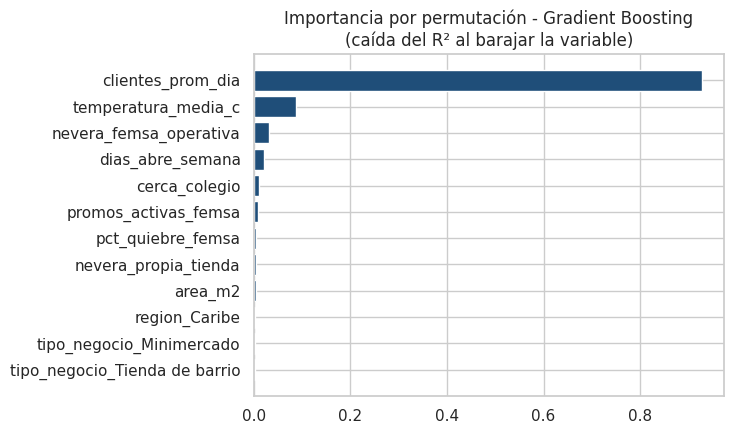

Coeficientes estandarizados del Ridge (efecto en log-ventas por 1 desv. estándar):
clientes_prom_dia        0.49
temperatura_media_c      0.14
region_Caribe            0.10
nevera_femsa_operativa   0.09
dias_abre_semana         0.08
cerca_colegio            0.07
region_Centro            0.06
promos_activas_femsa     0.06
dtype: float64


In [11]:
# Variables más importantes (importancia por permutación en prueba, mejor modelo)
imp = permutation_importance(modelos[mejor], X_te, y_te, n_repeats=5, random_state=SEED, n_jobs=-1)
imp = pd.Series(imp.importances_mean, index=X.columns).sort_values(ascending=False)
top = imp.head(12)[::-1]
plt.figure(figsize=(7.5, 4.5))
plt.barh(top.index, top.values, color=AZUL)
plt.title(f"Importancia por permutación - {mejor}\n(caída del R² al barajar la variable)")
plt.tight_layout(); plt.show()

# Sentido de las variables clave (coeficientes estandarizados del Ridge)
ridge = modelos["Ridge (base lineal)"]
coef = pd.Series(ridge[-1].coef_, index=X.columns).sort_values(key=np.abs, ascending=False).head(8)
print("Coeficientes estandarizados del Ridge (efecto en log-ventas por 1 desv. estándar):")
print(coef.round(3))

In [12]:
conf = ["region", "zona", "estrato", "temperatura_media_c", "poblacion_500m", "n_tiendas_competencia_500m",
        "dist_hard_discount_km", "cerca_colegio", "cerca_parada_transporte", "cerca_universidad_oficinas",
        "dist_cedi_km", "tipo_negocio", "area_m2", "antiguedad_anios", "dias_abre_semana", "horas_abre_dia",
        "num_empleados", "tiene_datafono", "acepta_pago_digital", "ofrece_domicilios", "tiene_mesas_consumo",
        "vende_licor", "n_referencias_total", "nevera_propia_tienda", "nevera_otras_marcas",
        "clientes_prom_dia", "nevera_postobon"]

# Muestra causal: control (sin nevera FEMSA) + tratadas (nevera FEMSA operativa)
muestra = df[(df.nevera_femsa == 0) | (df.nevera_femsa_operativa == 1)].copy()
T = muestra.nevera_femsa.values.astype(int)
Y = muestra[OBJETIVO].values
Xc = pd.get_dummies(muestra[conf], columns=["region", "zona", "tipo_negocio"], drop_first=True).astype(float)
print(f"Muestra causal: {len(muestra):,} | tratadas: {T.sum():,} | control: {(1 - T).sum():,} "
      f"| excluidas (nevera dañada): {len(df) - len(muestra):,}")

# 4.1 Comparación simple de promedios
dif_simple = Y[T == 1].mean() - Y[T == 0].mean()
print(f"\n(1) Diferencia simple de promedios: {dif_simple:,.0f} COP/mes")

Muestra causal: 34,198 | tratadas: 21,267 | control: 12,931 | excluidas (nevera dañada): 3,802

(1) Diferencia simple de promedios: 802,411 COP/mes


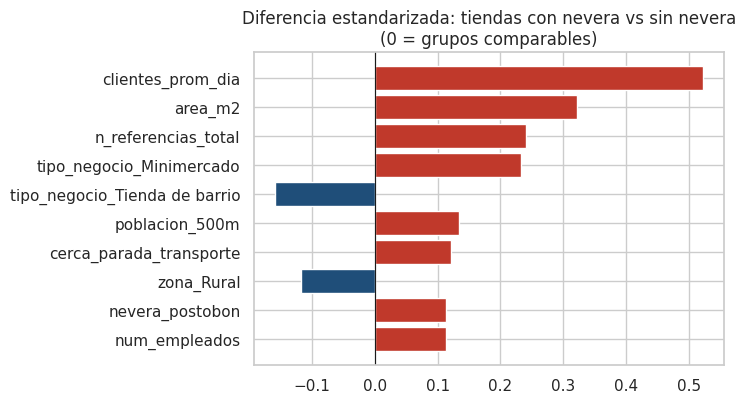

Propensión estimada: mín 0.07 | máx 0.94 | AUC 0.66 (hay solapamiento: no hay tiendas imposibles de comparar)


In [13]:
# 4.2 ¿Por qué la diferencia simple engaña? Diferencia estandarizada de medias entre tratadas y control
def smd(col):
    a, b = Xc.loc[T == 1, col], Xc.loc[T == 0, col]
    return (a.mean() - b.mean()) / np.sqrt((a.var() + b.var()) / 2)
desbalance = pd.Series({c: smd(c) for c in Xc.columns}).sort_values(key=np.abs, ascending=False)
top = desbalance.head(10)[::-1]
plt.figure(figsize=(7.5, 4.2))
plt.barh(top.index, top.values, color=[ROJO if v > 0 else AZUL for v in top.values])
plt.axvline(0, color="k", lw=0.8)
plt.title("Diferencia estandarizada: tiendas con nevera vs sin nevera\n(0 = grupos comparables)")
plt.tight_layout(); plt.show()

# Propensión a tener nevera (solapamiento: hay tiendas parecidas en ambos grupos)
cv_c = KFold(5, shuffle=True, random_state=SEED)
ps = cross_val_predict(HistGradientBoostingClassifier(max_iter=150, learning_rate=0.05, random_state=SEED),
                       Xc, T, cv=cv_c, method="predict_proba")[:, 1]
print(f"Propensión estimada: mín {ps.min():.2f} | máx {ps.max():.2f} | AUC {roc_auc_score(T, ps):.2f} "
      "(hay solapamiento: no hay tiendas imposibles de comparar)")

In [14]:
# 4.3 Cross-fitting: cada tienda se predice con modelos que NO la vieron al entrenar
def hgb():
    return HistGradientBoostingRegressor(max_iter=250, learning_rate=0.05, random_state=SEED)

mu1 = np.zeros(len(muestra)); mu0 = np.zeros(len(muestra)); tau_s = np.zeros(len(muestra))
Xs = Xc.copy(); Xs["T"] = T
for tr, te in cv_c.split(Xc):
    # T-learner
    m1 = hgb().fit(Xc.iloc[tr][T[tr] == 1], Y[tr][T[tr] == 1])
    m0 = hgb().fit(Xc.iloc[tr][T[tr] == 0], Y[tr][T[tr] == 0])
    mu1[te], mu0[te] = m1.predict(Xc.iloc[te]), m0.predict(Xc.iloc[te])
    # S-learner
    ms = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, random_state=SEED).fit(Xs.iloc[tr], Y[tr])
    a, b = Xs.iloc[te].copy(), Xs.iloc[te].copy(); a["T"], b["T"] = 1, 0
    tau_s[te] = ms.predict(a) - ms.predict(b)

tau_t = mu1 - mu0
muestra["tau_T"], muestra["tau_S"] = tau_t, tau_s
muestra["tau"] = (tau_t + tau_s) / 2          # efecto final: ventas adicionales por la nevera (COP/mes)

# Estimador doblemente robusto (AIPW) como verificación del efecto promedio
e = np.clip(ps, 0.02, 0.98)
aipw_i = (mu1 - mu0) + T * (Y - mu1) / e - (1 - T) * (Y - mu0) / (1 - e)

ctrl = (T == 0)
resumen = pd.Series({
    "(1) Diferencia simple de promedios": dif_simple,
    "(2) T-learner, efecto en tiendas sin nevera": tau_t[ctrl].mean(),
    "(3) S-learner, efecto en tiendas sin nevera": tau_s[ctrl].mean(),
    "(4) Efecto final (promedio T y S)": muestra.tau[ctrl].mean(),
    "(5) AIPW, efecto promedio (todas)": aipw_i.mean(),
}, name="COP adicionales / mes por tienda")
display(resumen.to_frame())
print(f"La comparación simple sobrestima el efecto en {dif_simple / muestra.tau[ctrl].mean() - 1:.0%} "
      "porque confunde el efecto de la nevera con que esas tiendas ya eran más grandes.")

,COP adicionales / mes por tienda
(1) Diferencia simple de promedios,"802,410.82"
"(2) T-learner, efecto en tiendas sin nevera","323,256.66"
"(3) S-learner, efecto en tiendas sin nevera","281,802.88"
(4) Efecto final (promedio T y S),"302,529.77"
"(5) AIPW, efecto promedio (todas)","414,824.21"


La comparación simple sobrestima el efecto en 165% porque confunde el efecto de la nevera con que esas tiendas ya eran más grandes.


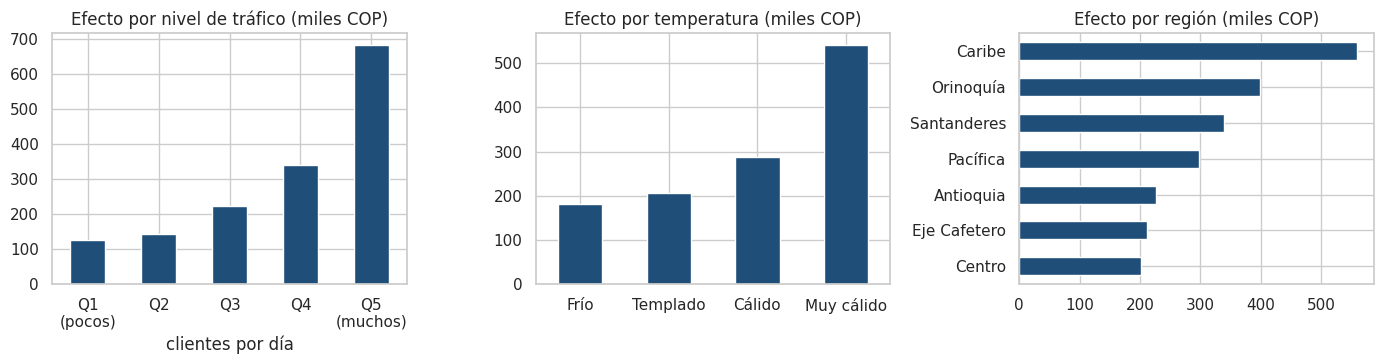

In [15]:
# 4.4 ¿Dónde rinde más la nevera? (heterogeneidad del efecto en tiendas sin nevera)
sin = muestra[muestra.nevera_femsa == 0].copy()
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
sin.groupby(pd.qcut(sin.clientes_prom_dia, 5, labels=["Q1\n(pocos)", "Q2", "Q3", "Q4", "Q5\n(muchos)"])).tau.mean().div(1e3).plot.bar(color=AZUL, ax=ax[0], rot=0)
ax[0].set(title="Efecto por nivel de tráfico (miles COP)", xlabel="clientes por día", ylabel="")
sin.groupby(pd.qcut(sin.temperatura_media_c, 4, labels=["Frío", "Templado", "Cálido", "Muy cálido"])).tau.mean().div(1e3).plot.bar(color=AZUL, ax=ax[1], rot=0)
ax[1].set(title="Efecto por temperatura (miles COP)", xlabel="", ylabel="")
sin.groupby("region").tau.mean().div(1e3).sort_values().plot.barh(color=AZUL, ax=ax[2])
ax[2].set(title="Efecto por región (miles COP)", xlabel="", ylabel="")
plt.tight_layout(); plt.show()

In [16]:
OBJ_R = "cambio_proveedor_principal_6m"
yr = df[OBJ_R].values
Xr_raw = df.drop(columns=[OBJ_R] + cols_id_geo + cols_sku + cols_aux)
Xr = pd.get_dummies(Xr_raw, columns=Xr_raw.select_dtypes(exclude="number").columns.tolist(), drop_first=True).astype(float)
print(f"Tasa de cambio: {yr.mean():.1%} | variables: {Xr.shape[1]}")

cv_r = StratifiedKFold(5, shuffle=True, random_state=SEED)
candidatos = {
    "Logística (sin pesos)": make_pipeline(StandardScaler(), LogisticRegression(max_iter=500)),
    "Logística (balanceada)": make_pipeline(StandardScaler(), LogisticRegression(max_iter=500, class_weight="balanced")),
    "Random Forest (balanceado)": RandomForestClassifier(n_estimators=150, min_samples_leaf=20, max_samples=0.6,
                                                         class_weight="balanced_subsample", n_jobs=-1, random_state=SEED),
    "Gradient Boosting (sin pesos)": HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05, random_state=SEED),
    "Gradient Boosting (balanceado)": HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05,
                                                                     class_weight="balanced", random_state=SEED),
}
filas = []
for nombre, m in candidatos.items():
    p = cross_val_predict(m, Xr, yr, cv=cv_r, method="predict_proba")[:, 1]
    filas.append({"modelo": nombre, "ROC-AUC": roc_auc_score(yr, p), "PR-AUC": average_precision_score(yr, p)})
cmp_riesgo = pd.DataFrame(filas).set_index("modelo")
display(cmp_riesgo)
print(f"Referencia PR-AUC de un modelo sin información = {yr.mean():.3f}")

Tasa de cambio: 9.5% | variables: 75


,ROC-AUC,PR-AUC
modelo,,
Logística (sin pesos),0.75,0.28
Logística (balanceada),0.75,0.27
Random Forest (balanceado),0.80,0.34
Gradient Boosting (sin pesos),0.82,0.40
Gradient Boosting (balanceado),0.82,0.39


Referencia PR-AUC de un modelo sin información = 0.095


ROC-AUC 0.822 | PR-AUC 0.404 | prob. media predicha 0.095 vs tasa real 0.095 (calibración)


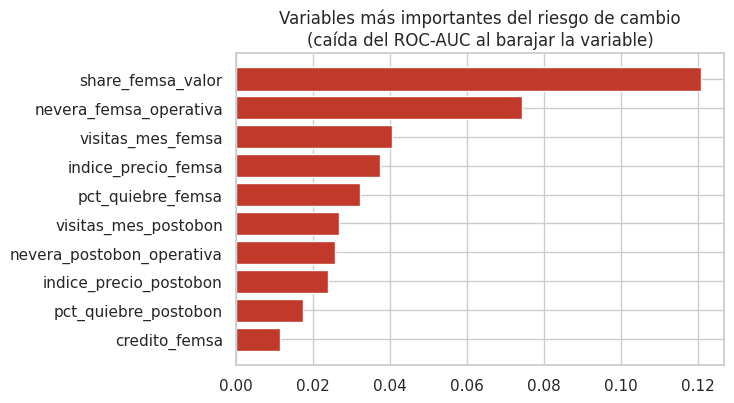

In [17]:
# Modelo final: Gradient Boosting con probabilidades CALIBRADAS (las necesitamos como probabilidades reales
# para aplicar el umbral de costos). p_cambio se obtiene fuera de muestra para las 38.000 tiendas.
final_riesgo = CalibratedClassifierCV(HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05, random_state=SEED),
                                      method="isotonic", cv=3)
df["p_cambio"] = cross_val_predict(final_riesgo, Xr, yr, cv=cv_r, method="predict_proba")[:, 1]
print(f"ROC-AUC {roc_auc_score(yr, df.p_cambio):.3f} | PR-AUC {average_precision_score(yr, df.p_cambio):.3f} "
      f"| prob. media predicha {df.p_cambio.mean():.3f} vs tasa real {yr.mean():.3f} (calibración)")

# Variables que más explican el riesgo
m_imp = HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05, random_state=SEED).fit(Xr, yr)
muestra_imp = Xr.sample(6000, random_state=SEED)
imp_r = permutation_importance(m_imp, muestra_imp, yr[muestra_imp.index], scoring="roc_auc", n_repeats=3,
                               random_state=SEED, n_jobs=-1)
imp_r = pd.Series(imp_r.importances_mean, index=Xr.columns).sort_values(ascending=False).head(10)[::-1]
plt.figure(figsize=(7.5, 4.2)); plt.barh(imp_r.index, imp_r.values, color=ROJO)
plt.title("Variables más importantes del riesgo de cambio\n(caída del ROC-AUC al barajar la variable)")
plt.tight_layout(); plt.show()

Umbral teórico: 0.25


,tiendas con acción,beneficio esperado (M COP),beneficio con datos reales (M COP)
umbral,,,
0.05,18776,-317.80,-309.00
0.10,10281,-11.31,-1.45
0.15,6745,78.78,95.95
0.20,4838,108.43,120.70
0.25,3589,115.51,128.15
0.30,2729,111.33,119.35
0.35,2058,101.64,109.30
0.40,1566,89.48,94.10
0.45,1186,76.27,82.50


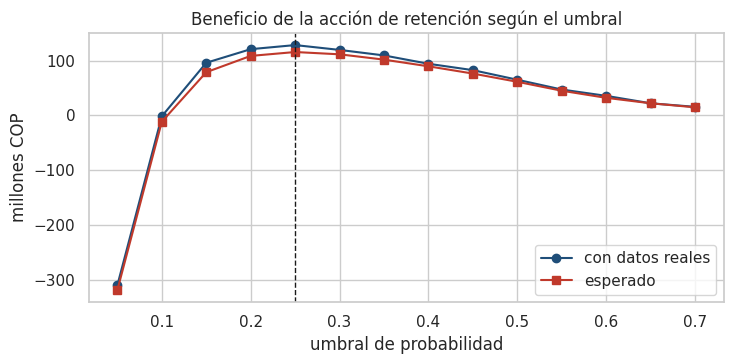

Tiendas de riesgo alto en toda la base: 3,589 (9.4%)


In [18]:
umbral_teorico = COSTO_RETENCION / (EFECT_RETENCION * VALOR_NO_CAMBIO)
print(f"Umbral teórico: {umbral_teorico:.2f}")

umbrales = np.round(np.arange(0.05, 0.71, 0.05), 2)
filas = []
for u in umbrales:
    act = df.p_cambio >= u
    # beneficio esperado con las probabilidades calibradas, y beneficio "realizado" con los cambios reales
    esperado = (EFECT_RETENCION * df.p_cambio[act] * VALOR_NO_CAMBIO - COSTO_RETENCION).sum()
    real = (EFECT_RETENCION * yr[act] * VALOR_NO_CAMBIO - COSTO_RETENCION).sum()
    filas.append({"umbral": u, "tiendas con acción": int(act.sum()), "beneficio esperado (M COP)": esperado / 1e6,
                  "beneficio con datos reales (M COP)": real / 1e6})
tabla_u = pd.DataFrame(filas).set_index("umbral")
display(tabla_u)
UMBRAL = umbral_teorico
plt.figure(figsize=(7.5, 3.8))
plt.plot(tabla_u.index, tabla_u["beneficio con datos reales (M COP)"], marker="o", color=AZUL, label="con datos reales")
plt.plot(tabla_u.index, tabla_u["beneficio esperado (M COP)"], marker="s", color=ROJO, label="esperado")
plt.axvline(UMBRAL, color="k", ls="--", lw=1); plt.legend(); plt.xlabel("umbral de probabilidad")
plt.title("Beneficio de la acción de retención según el umbral"); plt.ylabel("millones COP")
plt.tight_layout(); plt.show()
df["riesgo_alto"] = (df.p_cambio >= UMBRAL).astype(int)
print(f"Tiendas de riesgo alto en toda la base: {df.riesgo_alto.sum():,} ({df.riesgo_alto.mean():.1%})")

In [19]:
elegible = (df.nevera_femsa == 0) & ~((df.nevera_postobon == 1) & (df.area_m2 < 12))
print(f"Tiendas elegibles: {elegible.sum():,} de {len(df):,}")

# Traemos el efecto estimado (solo existe para tiendas sin nevera / con nevera operativa; las elegibles están todas)
df["tau"] = muestra.tau.reindex(df.index)
el = df[elegible].copy()
el["ganancia_mensual"] = MARGEN * el.tau - COSTO_NEVERA
print(f"Elegibles con ganancia esperada > 0: {(el.ganancia_mensual > 0).sum():,}")

def evalua(sel, nombre):
    return {"regla": nombre,
            "tiendas": len(sel),
            "ventas adicionales (M COP/mes)": sel.tau.sum() / 1e6,
            "ganancia mensual total (M COP)": sel.ganancia_mensual.sum() / 1e6,
            "ganancia media por tienda (COP)": sel.ganancia_mensual.mean(),
            "tiendas con ganancia > 0": int((sel.ganancia_mensual > 0).sum()),
            "riesgo alto (p ≥ 0,25)": int(sel.riesgo_alto.sum())}

sel_modelo = el.nlargest(N_NEVERAS, "ganancia_mensual")
sel_ventas = el.nlargest(N_NEVERAS, OBJETIVO)
sel_trafico = el.nlargest(N_NEVERAS, "clientes_prom_dia")
comparacion = pd.DataFrame([evalua(sel_modelo, "Modelo (mayor ganancia estimada)"),
                            evalua(sel_ventas, "Regla 1: mayores ventas actuales"),
                            evalua(sel_trafico, "Regla 2: mayor tráfico")]).set_index("regla")
display(comparacion)

Tiendas elegibles: 12,700 de 38,000
Elegibles con ganancia esperada > 0: 5,021


,tiendas,ventas adicionales (M COP/mes),ganancia mensual total (M COP),ganancia media por tienda (COP),tiendas con ganancia > 0,"riesgo alto (p ≥ 0,25)"
regla,,,,,,
Modelo (mayor ganancia estimada),1000,"1,212.77",243.19,"243,191.50",1000,129
Regla 1: mayores ventas actuales,1000,881.97,160.49,"160,492.85",913,130
Regla 2: mayor tráfico,1000,946.99,176.75,"176,748.31",974,128


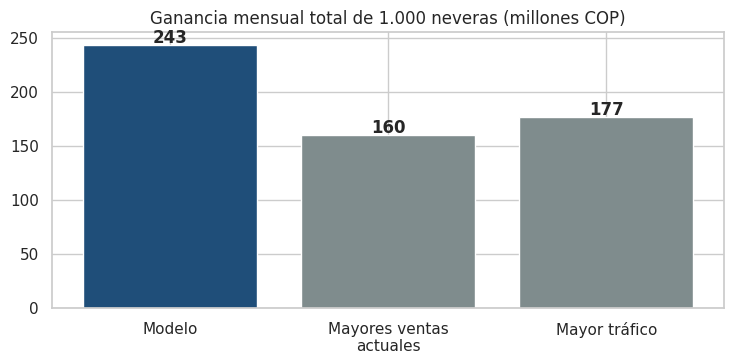

Tiendas en común del modelo con la regla de ventas: 472 y con la de tráfico: 508


In [20]:
g = comparacion["ganancia mensual total (M COP)"]
plt.figure(figsize=(7.5, 3.8))
bars = plt.bar(["Modelo", "Mayores ventas\nactuales", "Mayor tráfico"], g.values, color=[AZUL, GRIS, GRIS])
for b_, v in zip(bars, g.values):
    plt.text(b_.get_x() + b_.get_width() / 2, v + 2, f"{v:,.0f}", ha="center", fontweight="bold")
plt.title("Ganancia mensual total de 1.000 neveras (millones COP)"); plt.ylabel("")
plt.tight_layout(); plt.show()

sol = len(set(sel_modelo.index) & set(sel_ventas.index)), len(set(sel_modelo.index) & set(sel_trafico.index))
print(f"Tiendas en común del modelo con la regla de ventas: {sol[0]} y con la de tráfico: {sol[1]}")

In [21]:
# Perfil de las 1.000 tiendas elegidas vs el resto de elegibles
perfil = pd.DataFrame({
    "Elegidas (1.000)": sel_modelo[["clientes_prom_dia", "temperatura_media_c", "area_m2", "ventas_femsa_cop_mes", "tau", "p_cambio"]].mean(),
    "Resto de elegibles": el.drop(sel_modelo.index)[["clientes_prom_dia", "temperatura_media_c", "area_m2", "ventas_femsa_cop_mes", "tau", "p_cambio"]].mean()})
display(perfil)
display(sel_modelo.region.value_counts().to_frame("tiendas elegidas por región"))

,Elegidas (1.000),Resto de elegibles
clientes_prom_dia,109.48,55.53
temperatura_media_c,25.77,20.73
area_m2,52.96,33.64
ventas_femsa_cop_mes,"2,005,041.25","789,753.33"
tau,"1,212,766.00","225,553.09"
p_cambio,0.12,0.15


,tiendas elegidas por región
region,
Caribe,557
Pacífica,119
Centro,114
Santanderes,71
Antioquia,68
Orinoquía,42
Eje Cafetero,29


In [22]:
# Lista final y descarga
lista = sel_modelo[["id_tienda", "region", "ciudad", "tipo_negocio", "area_m2", "clientes_prom_dia",
                    OBJETIVO, "tau", "ganancia_mensual", "p_cambio", "riesgo_alto"]].rename(
    columns={OBJETIVO: "ventas_femsa_actuales", "tau": "ventas_adicionales_est"}).sort_values("ganancia_mensual", ascending=False)
lista.insert(0, "ranking", range(1, len(lista) + 1))
assert len(lista) == N_NEVERAS and lista.id_tienda.is_unique and elegible[lista.index].all()
lista.to_csv("lista_1000_tiendas.csv", index=False)
display(lista.head(10))

print("\n===== RESUMEN =====")
print(f"Tiendas elegidas: {len(lista):,}")
print(f"Ganancia mensual total estimada: {lista.ganancia_mensual.sum():,.0f} COP (≈ {lista.ganancia_mensual.sum() / 1e6:,.0f} millones)")
print(f"Ganancia anual aproximada: {12 * lista.ganancia_mensual.sum() / 1e6:,.0f} millones COP")
print(f"Tiendas de la lista con riesgo alto de cambio (p ≥ {UMBRAL:.2f}): {lista.riesgo_alto.sum()}")
try:
    from google.colab import files
    files.download("lista_1000_tiendas.csv")
except ImportError:
    pass

,ranking,id_tienda,region,ciudad,tipo_negocio,area_m2,clientes_prom_dia,ventas_femsa_actuales,ventas_adicionales_est,ganancia_mensual,p_cambio,riesgo_alto
20065,1,T20066,Caribe,Valledupar,Minimercado,164.70,235,4660000,"5,529,342.95","1,322,335.74",0.01,0
11811,2,T11812,Caribe,Barranquilla,Minimercado,177.80,225,3793070,"4,199,688.83","989,922.21",0.05,0
5255,3,T05256,Pacífica,Cali,Minimercado,104.70,237,3309910,"4,053,737.48","953,434.37",0.05,0
9760,4,T09761,Caribe,Barranquilla,Panadería,35.40,157,4087520,"3,877,712.16","909,428.04",0.01,0
23114,5,T23115,Caribe,Barranquilla,Tienda de barrio,47.00,160,4444490,"3,721,152.57","870,288.14",0.01,0
20611,6,T20612,Caribe,Barranquilla,Minimercado,218.60,188,9924130,"3,534,243.50","823,560.87",0.06,0
27781,7,T27782,Caribe,Santa Marta,Minimercado,181.10,172,3394750,"3,498,744.26","814,686.06",0.04,0
32153,8,T32154,Caribe,Valledupar,Minimercado,109.10,151,2874800,"3,438,813.18","799,703.30",0.31,1
22151,9,T22152,Caribe,Montería,Tienda de barrio,25.20,140,3247940,"3,392,939.93","788,234.98",0.05,0
23383,10,T23384,Caribe,Santa Marta,Minimercado,135.80,148,2181160,"3,210,369.45","742,592.36",0.44,1



===== RESUMEN =====
Tiendas elegidas: 1,000
Ganancia mensual total estimada: 243,191,500 COP (≈ 243 millones)
Ganancia anual aproximada: 2,918 millones COP
Tiendas de la lista con riesgo alto de cambio (p ≥ 0.25): 129


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Limitaciones y supuestos
- **Causalidad observacional:** el efecto de la nevera se identifica asumiendo que las variables de ajuste capturan lo que hace que una tienda reciba nevera (sin confusores no observados). Los datos son simulados, así que no se pueden validar contra un experimento.
- **Efecto estimado, no observado:** el efecto por tienda es una estimación ruidosa; al escoger las 1.000 mejores hay algo de optimismo (*maldición del ganador*). Por eso promediamos dos métodos y verificamos con AIPW.
- Las reglas simples se valoran con el mismo estimador del efecto, lo que favorece al modelo; la comparación es indicativa.
- Se excluyeron variables posteriores a la nevera (visitas, quiebres, promociones, precios) del ajuste causal para evitar sesgo.